Entropy: 1.0
Gini: 0.5
Iris dataset: 150 samples, 4 features

Decision Tree with Entropy (Information Gain)
Accuracy: 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


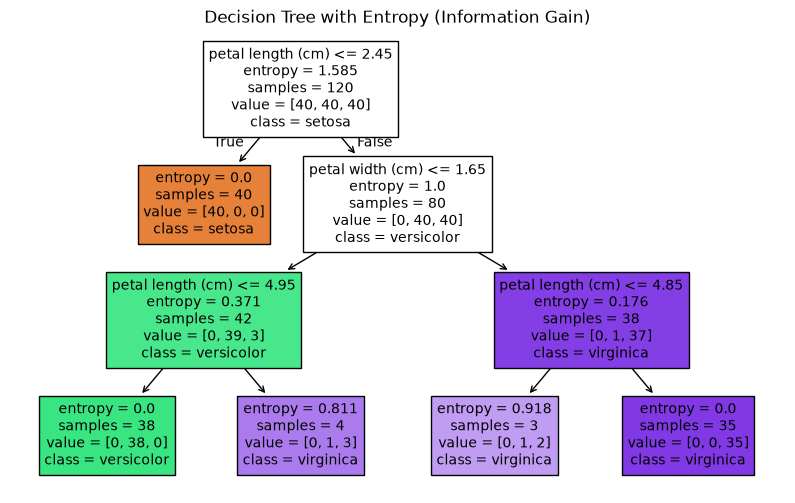


Decision Tree with Gini Impurity
Accuracy: 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


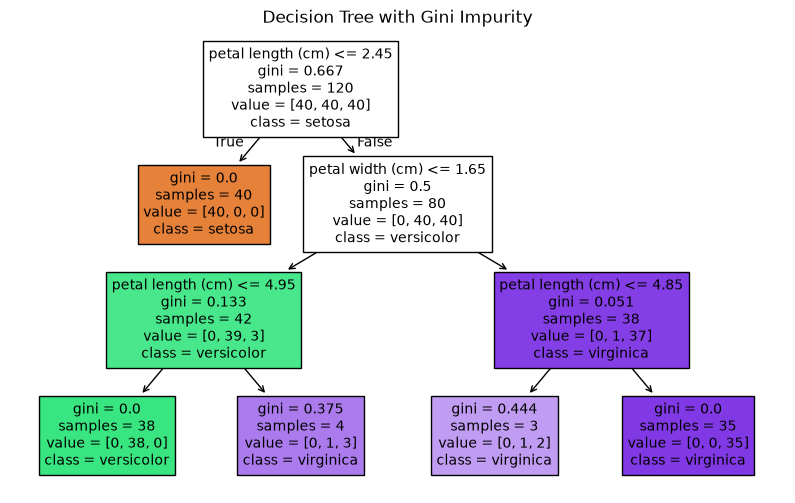


Feature Importance (Entropy Model):
sepal length (cm): 0.0000
sepal width (cm): 0.0000
petal length (cm): 0.6865
petal width (cm): 0.3135


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# --------------------------------------------------
# 1. Entropy and Gini impurity calculations
# --------------------------------------------------
def entropy(labels):
    labels = np.asarray(labels)
    n = len(labels)
    if n == 0:
        return 0
    _, counts = np.unique(labels, return_counts=True)
    probs = counts / n
    return -np.sum(probs * np.log2(probs + 1e-12))

def gini(labels):
    labels = np.asarray(labels)
    n = len(labels)
    if n == 0:
        return 0
    _, counts = np.unique(labels, return_counts=True)
    probs = counts / n
    return 1 - np.sum(probs ** 2)

# Example of entropy and Gini for a simple binary class split
sample_labels = np.array([1, 1, 0, 0])
print("Entropy:", round(entropy(sample_labels), 4))
print("Gini:", round(gini(sample_labels), 4))

# --------------------------------------------------
# 2. Decision Tree Classification
# --------------------------------------------------
iris = load_iris()
print("Iris dataset:", iris.data.shape[0], "samples,", iris.data.shape[1], "features")
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Decision Tree using entropy (Information Gain)
dt_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
dt_entropy.fit(X_train, y_train)
y_pred_entropy = dt_entropy.predict(X_test)

# Decision Tree using Gini impurity
dt_gini = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
dt_gini.fit(X_train, y_train)
y_pred_gini = dt_gini.predict(X_test)

# Evaluate both models
for name, model, y_pred in [
    ("Decision Tree with Entropy (Information Gain)", dt_entropy, y_pred_entropy),
    ("Decision Tree with Gini Impurity", dt_gini, y_pred_gini)
]:
    acc = accuracy_score(y_test, y_pred)
    print(f"\n{name}")
    print("Accuracy:", round(acc, 4))
    print(classification_report(y_test, y_pred, target_names=iris.target_names))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    
    plt.figure(figsize=(10, 6))
    plot_tree(model, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
    plt.title(name)
    plt.show()

# --------------------------------------------------
# 3. Feature importance
# --------------------------------------------------
print("\nFeature Importance (Entropy Model):")
for feature, importance in zip(iris.feature_names, dt_entropy.feature_importances_):
    print(f"{feature}: {importance:.4f}")

In [2]:
from sklearn.naive_bayes import GaussianNB
classifier = GaussianNB()
classifier.fit(X_train,y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](3,)","[40.,40.,40.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](3,)","[0.33,0.33,0.33]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](3,)","[0,1,2]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,3.102e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](3, 4)","[[4.99,3.41,1.48,0.25], [5.93,2.75,4.25,1.32], [6.61,2.98,5.58,2.04]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](3, 4)","[[0.09,0.16,0.03,0.01], [0.22,0.09,0.19,0.03], [0.46,0.12,0.32,0.07]]"


In [3]:
y_pred = classifier.predict(X_test)
y_pred

array([0, 2, 1, 1, 0, 1, 0, 0, 2, 1, 2, 2, 2, 1, 0, 0, 0, 1, 1, 2, 0, 2,
       1, 2, 2, 2, 1, 0, 2, 0])

In [4]:
from sklearn.metrics import accuracy_score
prediction = accuracy_score(y_test, y_pred)
print(prediction * 100)

96.66666666666667


In [5]:
from sklearn.neighbors import KNeighborsClassifier
classifier = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)
classifier.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [7]:
X_train = np.array([(2, 4), (4, 4), (4, 6), (6, 8)])
y_train = np.array(["Red", "Red", "Blue", "Blue"])

test_point = np.array([[5, 5]])
k = 3

knn_model = KNeighborsClassifier(n_neighbors=k)
knn_model.fit(X_train, y_train)

print("Predicted class:", knn_model.predict(test_point)[0])


Predicted class: Red


In [8]:
import math
from collections import Counter

In [9]:
def euclidean_distance(p1, p2):
    return math.sqrt(sum((a - b) ** 2 for a, b in zip(p1, p2)))

In [11]:
def knn(train_data, train_labels, test_point, k):
    distances = []
    for i in range(len(train_data)):
        dist = euclidean_distance(train_data[i], test_point)
        distances.append((dist, train_labels[i]))
    
    distances.sort(key=lambda x: x[0])
    k_nearest_neighbors = distances[:k]
    
    k_nearest_labels = [label for _, label in k_nearest_neighbors]

    return Counter(k_nearest_labels).most_common(1)[0][0]

In [12]:
X_train = np.array([(2, 4), (4, 4), (4, 6), (6, 8)])
y_train = np.array(["Red", "Red", "Blue", "Blue"])

test_point = np.array([[5, 5]])
k = 3
print("Predicted class:", knn(X_train, y_train, test_point[0], k))

Predicted class: Red
